# Peloton | Subscription Churn Analysis

**An evidence-based investigation of customer cancellation patterns and retention opportunities**  
**Observation window:** July 2024 – December 2025  
**Data:** 4,200 customers and 30,525 unique customer-month usage records

## Executive Summary

This analysis identifies three substantial **associations** with subscriber cancellations:

1. **Low early engagement.** Subsequent 90-day churn is **30.91%** among customers with no workouts in their signup month versus **8.87%** among those with six or more.
2. **Promotional acquisition.** Initial 90-day churn is **28.36%** for Promo Offer versus **10.02%** for Referral. Among monthly subscribers, the gap is **43.90% vs. 15.17%**.
3. **Annual subscription lifecycle.** Cancellations concentrate around days 300–359 of annual subscriptions. The preliminary 30-day cancellation proportion reaches **42.54%** at days 330–359 versus **4.31%** for monthly plans at the same tenure stage.

These are observational findings, **not proven causes**. The annual-tenure estimates do not fully correct for partial interval follow-up; renewal event records are unavailable. The recommended actions and measurement plan appear in Section 8.

## 1. Business Context & Analytical Framework

**Business question:** Why do fitness-app subscribers cancel, and what should the membership team prioritize to improve retention?

**Research questions**

- How does churn change over calendar time and subscription tenure?
- Which subscription attributes and acquisition channels are linked to early cancellations?
- Do signup-month workouts, class bookings, and support contact predict later cancellation?
- Are observed behavior patterns consistent with self-reported cancellation reasons?

**Primary outcome definitions**

- **Churned:** `churned == 'yes'` and a cancellation date on or before **2025-12-31**.
- **Observed tenure:** days from `signup_date` to `churn_date` for churned customers, or to 2025-12-31 for active customers (right-censored).
- **Monthly churn proportion:** cancellations in a calendar month / customers subscribed for any part of that month. Partial-month exposure is counted as one person, not prorated.
- **First 90-day cumulative churn:** cancellation within days 0–89 since signup, restricted to customers with at least 90 days of potential follow-up.
- **Subsequent 90-day churn:** cancellation during the 90 days after the *calendar month of signup*, for customers still active at its end and with complete potential follow-up.

**Key assumptions and limitations**

1. Each `subscriptions.csv` customer appears once; each deduplicated `usage.csv` customer-month appears once.
2. Signup-month engagement is calendar-month activity, **not a uniform first 30 days**. Available exposure differs by signup day.
3. The dataset has no detailed renewal events, offer expiries, workout timestamps, or customer-reported reasons for every cancellation.
4. Descriptive stratification reduces selected biases but does not establish causal effects or fully adjust for customer mix.

## 2. Data Preparation

### 2.1 Load data and inspect structure

Files are loaded using **relative paths** so the project runs from its repository directory. No model training is required for this analysis.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OBS_END = pd.Timestamp('2025-12-31')
DATA_DIR = Path('data')

subs = pd.read_csv(DATA_DIR / 'subscriptions.csv')
usage = pd.read_csv(DATA_DIR / 'usage.csv')

plt.rcParams.update({
    'figure.figsize': (9, 4.8),
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': False,
    'savefig.bbox': 'tight',
})

pd.DataFrame({
    'dataset': ['subscriptions', 'usage'],
    'rows': [len(subs), len(usage)],
    'columns': [subs.shape[1], usage.shape[1]],
    'unique_customers': [subs.customer_id.nunique(), usage.customer_id.nunique()],
})

,dataset,rows,columns,unique_customers
0,subscriptions,4200,11,4200
1,usage,30685,6,4200


In [2]:
print('Subscriptions')
print(subs.dtypes.to_string())
print()
print('Usage')
print(usage.dtypes.to_string())
display(subs.head(3), usage.head(3))

Subscriptions
customer_id              int64
signup_date             object
plan_type               object
plan_tier               object
monthly_price          float64
acquisition_channel     object
primary_device          object
age_group               object
churned                 object
churn_date              object
cancel_reason           object

Usage
customer_id             int64
month                  object
workouts_completed      int64
minutes_active        float64
classes_booked          int64
support_tickets         int64


,customer_id,signup_date,plan_type,plan_tier,monthly_price,acquisition_channel,primary_device,age_group,churned,churn_date,cancel_reason
0,1,2024-09-11,monthly,basic,12.99,promo_offer,android,45-54,yes,2025-06-29,technical_issues
1,2,2025-08-14,annual,basic,9.74,promo_offer,web,45-54,no,NaN,NaN
2,3,2025-01-24,monthly,basic,12.99,referral,ios,55+,no,NaN,NaN


,customer_id,month,workouts_completed,minutes_active,classes_booked,support_tickets
0,1,2024-09,5,140.0,0,0
1,1,2024-10,4,116.0,0,0
2,1,2024-11,7,208.0,0,0


### 2.2 Quality audit and cleaning decisions

We inspect exact and customer-month duplicates, missing values, and category consistency before applying transformations. Only duplicate usage records and inconsistent tier labels require direct changes. Missing cancellation dates and reasons are meaningful or unknown, not automatically invalid.

In [3]:
quality_audit = pd.DataFrame({
    'dataset': ['subscriptions', 'usage'],
    'duplicate_rows': [subs.duplicated().sum(), usage.duplicated().sum()],
    'duplicate_keys': [subs.duplicated('customer_id').sum(),
                       usage.duplicated(['customer_id', 'month']).sum()],
})
missing_subs = subs.isna().sum().loc[lambda s: s > 0].rename('missing_count').to_frame()
missing_usage = usage.isna().sum().loc[lambda s: s > 0].rename('missing_count').to_frame()
display(quality_audit, missing_subs, missing_usage)
print('Plan tiers before cleaning:', sorted(subs['plan_tier'].unique()))

,dataset,duplicate_rows,duplicate_keys
0,subscriptions,0,0
1,usage,160,160


,missing_count
churn_date,2432
cancel_reason,2814


,missing_count
minutes_active,506


Plan tiers before cleaning: ['Basic', 'Plus', 'Premium', 'basic', 'plus', 'premium']


In [4]:
usage = usage.drop_duplicates().copy()
subs['plan_tier'] = subs['plan_tier'].str.strip().str.lower()
subs['signup_date'] = pd.to_datetime(subs['signup_date'])
subs['churn_date'] = pd.to_datetime(subs['churn_date'])
usage['month'] = pd.to_datetime(usage['month'])

assert subs['customer_id'].is_unique
assert not usage.duplicated(['customer_id', 'month']).any()
assert set(usage['customer_id']) == set(subs['customer_id'])
assert set(subs['plan_tier']) == {'basic', 'plus', 'premium'}
print(f'Clean rows: {len(subs):,} subscriptions, {len(usage):,} usage records')

Clean rows: 4,200 subscriptions, 30,525 usage records


In [5]:
quality_checks = pd.Series({
    'Churned with missing cancellation date':
        ((subs['churned'] == 'yes') & subs['churn_date'].isna()).sum(),
    'Active with a cancellation date':
        ((subs['churned'] == 'no') & subs['churn_date'].notna()).sum(),
    'Active with a cancellation reason':
        ((subs['churned'] == 'no') & subs['cancel_reason'].notna()).sum(),
    'Churned without a cancellation reason':
        ((subs['churned'] == 'yes') & subs['cancel_reason'].isna()).sum(),
    'Missing activity minutes (deduplicated usage)': usage['minutes_active'].isna().sum(),
    'Missing minutes with completed workouts':
        (usage['minutes_active'].isna() & (usage['workouts_completed'] > 0)).sum(),
})
quality_checks.to_frame('records')

,records
Churned with missing cancellation date,0
Active with a cancellation date,0
Active with a cancellation reason,0
Churned without a cancellation reason,382
Missing activity minutes (deduplicated usage),503
Missing minutes with completed workouts,448


**Cleaning decisions**

- Removed **160** exact usage duplicates (30,685 → **30,525** monthly rows) and standardized six capitalization variants into `basic`, `plus`, and `premium`.
- Retained null `churn_date` for active subscriptions and null `cancel_reason` for **382** canceled subscriptions whose reason is unknown.
- Retained **503** missing `minutes_active` values after deduplication. **448** of these records report at least one workout; replacing missing minutes with zero would create false inactivity.
- Prefer completed workouts as the primary engagement measure. Dates are converted to pandas timestamps. No rows were dropped for missing values.

### 2.3 Date consistency

Validate the observation window and the ordering of signup/cancellation events before calculating tenure.

In [6]:
date_issues = pd.Series({
    'Cancellations before signup': (subs['churn_date'] < subs['signup_date']).sum(),
    'Cancellations after 2025-12-31': (subs['churn_date'] > OBS_END).sum(),
    'Signups after 2025-12-31': (subs['signup_date'] > OBS_END).sum(),
})
assert (date_issues == 0).all()
print(date_issues.to_string())
print('Signup range:', subs.signup_date.min().date(), 'to', subs.signup_date.max().date())
print('Usage range:', usage.month.min().date(), 'to', usage.month.max().date())

Cancellations before signup       0
Cancellations after 2025-12-31    0
Signups after 2025-12-31          0
Signup range: 2024-07-01 to 2025-10-30
Usage range: 2024-07-01 to 2025-12-01


## 3. Churn & Tenure Analysis

### 3.1 Define observed tenure

For active subscriptions, the study ends on December 31, 2025, rather than on an actual cancellation date. These observations are right-censored.

In [7]:
subs['end_date'] = subs['churn_date'].fillna(OBS_END)
subs['tenure_days'] = (subs['end_date'] - subs['signup_date']).dt.days
subs['tenure_period'] = subs['tenure_days'] // 30
subs['churn_month'] = subs['churn_date'].dt.to_period('M')

assert subs['tenure_days'].ge(0).all()
assert (subs['churned'] == 'yes').sum() == 1768
print('Observed median tenure (days) by outcome:')
display(subs.groupby('churned')['tenure_days'].median().to_frame('median_days'))

Observed median tenure (days) by outcome:


,median_days
churned,
no,229.0
yes,114.0


### 3.2 Monthly cancellation trend

For each calendar month, count everyone whose subscription overlaps at least one day of that month. The result is a **monthly cancellation proportion**, not a person-time-adjusted hazard. A month with many new signups and partial-month exposure can differ from a mature cohort.

In [8]:
months = pd.period_range('2024-07', '2025-12', freq='M')
monthly_cancellations = (
    subs.loc[subs['churned'] == 'yes']
        .groupby('churn_month').size().reindex(months, fill_value=0)
)
monthly_at_risk = pd.Series({
    m: ((subs['signup_date'] <= m.end_time) &
        (subs['end_date'] >= m.start_time)).sum()
    for m in months
})
monthly_churn = pd.DataFrame({
    'cancellations': monthly_cancellations,
    'at_risk': monthly_at_risk,
})
monthly_churn['churn_rate_pct'] = (
    monthly_churn['cancellations'] / monthly_churn['at_risk'] * 100
).round(2)
assert monthly_churn['cancellations'].sum() == 1768
display(monthly_churn)

,cancellations,at_risk,churn_rate_pct
2024-07,8,172,4.65
2024-08,14,359,3.90
2024-09,38,572,6.64
2024-10,36,785,4.59
2024-11,52,999,5.21
2024-12,54,1232,4.38
2025-01,77,1427,5.40
2025-02,81,1601,5.06
2025-03,103,1804,5.71
2025-04,98,1965,4.99


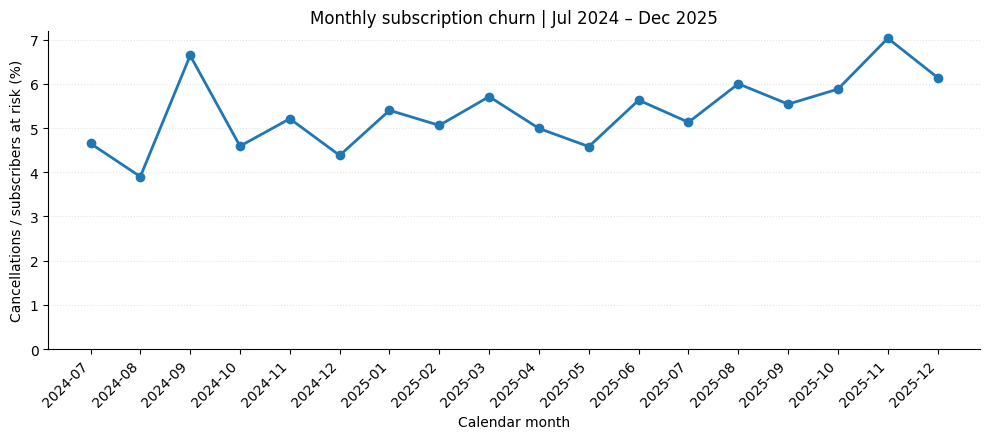

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(monthly_churn))
ax.plot(x, monthly_churn['churn_rate_pct'], marker='o', linewidth=2)
ax.set_xticks(x)
ax.set_xticklabels(monthly_churn.index.astype(str), rotation=45, ha='right')
ax.set_ylim(bottom=0)
ax.set_ylabel('Cancellations / subscribers at risk (%)')
ax.set_xlabel('Calendar month')
ax.set_title('Monthly subscription churn | Jul 2024 – Dec 2025')
ax.grid(axis='y', linestyle=':', alpha=0.35)
plt.tight_layout()
plt.show()

**Finding.** Mean monthly churn was **5.36%**, with a minimum of **3.90%** in August 2024 and a maximum of **7.03%** in November 2025. The rise in late 2025 requires caution: the data contain no new registrations after October 2025 and the subscriber mix changes over time.

### 3.3 Churn at comparable subscription ages

Group observed tenure into consecutive **30-day intervals**. The denominator for interval *k* includes everyone observed through its start (including those who survived beyond it); the numerator contains cancellations during that interval. Active customers whose follow-up ends within the interval are counted separately as censored.

We show both a simple interval proportion and an **approximate life-table adjustment** that subtracts half the censored observations from the risk set. This approximation assumes censoring is approximately uniform within each interval; it is not an exact survival estimate. Small risk sets near the end of the study warrant caution.

In [10]:
tenure_results = []
for period in range(subs['tenure_period'].max() + 1):
    start_day, end_day = period * 30, (period + 1) * 30
    at_risk = (subs['tenure_days'] >= start_day).sum()
    cancellations = (
        (subs['churned'] == 'yes') &
        subs['tenure_days'].between(start_day, end_day - 1)
    ).sum()
    censored = (
        (subs['churned'] == 'no') &
        subs['tenure_days'].between(start_day, end_day - 1)
    ).sum()
    tenure_results.append({
        'tenure_period': period,
        'at_risk': at_risk,
        'cancellations': cancellations,
        'censored': censored,
        'churn_rate_pct': round(cancellations / at_risk * 100, 2),
        'approx_adjusted_rate_pct': round(cancellations / (at_risk - censored / 2) * 100, 2),
    })
tenure_churn = pd.DataFrame(tenure_results)
assert tenure_churn['cancellations'].sum() == 1768
assert tenure_churn['censored'].sum() == 2432
display(tenure_churn)

,tenure_period,at_risk,cancellations,censored,churn_rate_pct,approx_adjusted_rate_pct
0,0,4200,267,0,6.36,6.36
1,1,3933,246,0,6.25,6.25
2,2,3687,239,239,6.48,6.70
3,3,3209,164,242,5.11,5.31
4,4,2803,114,227,4.07,4.24
5,5,2462,85,195,3.45,3.59
6,6,2182,78,198,3.57,3.74
7,7,1906,69,184,3.62,3.80
8,8,1653,44,184,2.66,2.82
9,9,1425,52,169,3.65,3.88


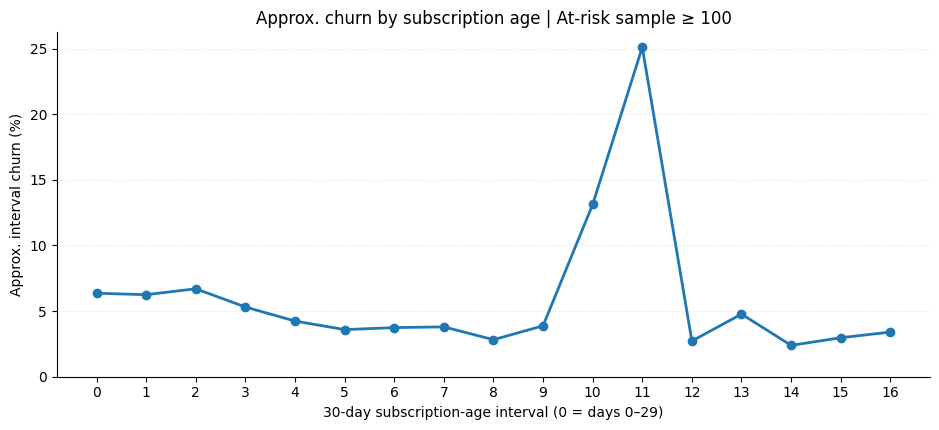

In [11]:
fig, ax = plt.subplots(figsize=(9.5, 4.4))
plot_tenure = tenure_churn.loc[tenure_churn['at_risk'] >= 100]
ax.plot(plot_tenure['tenure_period'], plot_tenure['approx_adjusted_rate_pct'],
        marker='o', linewidth=2)
ax.set_xlabel('30-day subscription-age interval (0 = days 0–29)')
ax.set_ylabel('Approx. interval churn (%)')
ax.set_title('Approx. churn by subscription age | At-risk sample ≥ 100')
ax.set_ylim(bottom=0)
ax.set_xticks(plot_tenure['tenure_period'])
ax.grid(axis='y', linestyle=':', alpha=0.35)
plt.tight_layout()
plt.show()

**Finding.** Approximate churn is around **6–7%** in the first 90 days and rises sharply at days **300–359** (**13.12%** in days 300–329 and **25.10%** in days 330–359). This is a lifecycle pattern, not proof that renewal or pricing caused cancellations.

## 4. Customer Segmentation

### 4.1 Subscription type and first-anniversary pattern

Compare annual and monthly subscribers at the same subscription age. Unlike the early 90-day cumulative analyses below, these 30-day interval proportions remain **unadjusted for within-interval censoring**.

In [12]:
near_anniversary = []
for period in [10, 11]:
    start_day, end_day = period * 30, (period + 1) * 30
    eligible = subs.loc[subs['tenure_days'] >= start_day].groupby('plan_type').size()
    canceled = subs.loc[
        (subs['churned'] == 'yes') &
        subs['tenure_days'].between(start_day, end_day - 1)
    ].groupby('plan_type').size()
    for plan in ['annual', 'monthly']:
        near_anniversary.append({
            'interval': f'{start_day}–{end_day - 1} days',
            'plan_type': plan,
            'at_risk': int(eligible.get(plan, 0)),
            'cancellations': int(canceled.get(plan, 0)),
            'churn_rate_pct': round(canceled.get(plan, 0) / eligible.get(plan, 1) * 100, 2),
        })
anniversary_rates = pd.DataFrame(near_anniversary)
display(anniversary_rates)

,interval,plan_type,at_risk,cancellations,churn_rate_pct
0,300–329 days,annual,648,115,17.75
1,300–329 days,monthly,556,32,5.76
2,330–359 days,annual,449,191,42.54
3,330–359 days,monthly,441,19,4.31


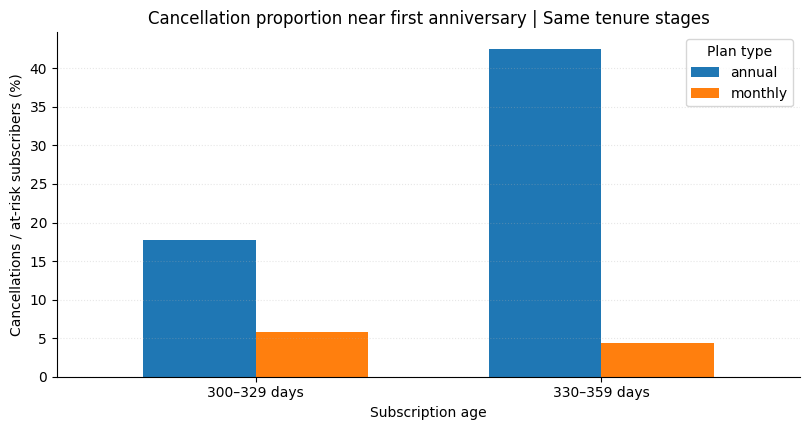

In [13]:
anniversary_plot = anniversary_rates.pivot(index='interval', columns='plan_type', values='churn_rate_pct')
ax = anniversary_plot[['annual', 'monthly']].plot.bar(figsize=(8.2, 4.4), rot=0, width=0.65)
ax.set_title('Cancellation proportion near first anniversary | Same tenure stages')
ax.set_xlabel('Subscription age')
ax.set_ylabel('Cancellations / at-risk subscribers (%)')
ax.set_ylim(bottom=0)
ax.legend(title='Plan type')
ax.grid(axis='y', linestyle=':', alpha=0.3)
plt.tight_layout()
plt.show()

**Finding.** At days **330–359**, annual subscriptions had **191 cancellations among 449 at-risk customers (42.54%)**, compared with **19 among 441 monthly subscribers (4.31%)**. This is a striking association with tenure and plan type, but the dataset cannot identify a renewal event or a definitive causal mechanism.

### 4.2 Early churn by customer segment

To avoid comparing customers with unequal opportunity to cancel, include only signups at least **90 days before** the observation end. An event must occur during days 0–89 after signup. This produces **90-day cumulative churn**, not a monthly rate.

In [14]:
cutoff_90 = OBS_END - pd.Timedelta(days=90)
early_eligible = subs.loc[subs['signup_date'] <= cutoff_90].copy()
early_eligible['churn_first_90d'] = (
    (early_eligible['churned'] == 'yes') &
    (early_eligible['tenure_days'] < 90)
)

def segment_churn(df, columns):
    result = df.groupby(columns, observed=True).agg(
        users=('churn_first_90d', 'size'),
        cancellations=('churn_first_90d', 'sum'),
        churn_rate_pct=('churn_first_90d', 'mean'),
    )
    result['churn_rate_pct'] = (result['churn_rate_pct'] * 100).round(2)
    return result

print(f'Eligible users: {len(early_eligible):,}')
display(segment_churn(early_eligible, 'plan_type'))

Eligible users: 3,915


,users,cancellations,churn_rate_pct
plan_type,,,
annual,1428,36,2.52
monthly,2487,670,26.94


### 4.3 Plan tier

Overall historical cancellation shares differ only slightly across Basic, Plus, and Premium; the comparable early 90-day results below are more meaningful.

In [15]:
plan_tier_rates = segment_churn(early_eligible, 'plan_tier').sort_values('churn_rate_pct', ascending=False)
display(plan_tier_rates)

,users,cancellations,churn_rate_pct
plan_tier,,,
premium,676,133,19.67
plus,1399,248,17.73
basic,1840,325,17.66


**Finding.** Premium shows **19.67%** early churn versus **17.66%** for Basic and **17.73%** for Plus. The spread is **2.01 percentage points**, much smaller than the differences by acquisition channel or initial workout engagement.

### 4.4 Acquisition channel

Compare the five sources of new subscribers on the same 90-day horizon. Then stratify by plan type to assess whether the channel association persists in comparable subscription plans.

In [16]:
channel_rates = segment_churn(early_eligible, 'acquisition_channel').sort_values('churn_rate_pct', ascending=False)
channel_by_plan = segment_churn(early_eligible, ['acquisition_channel', 'plan_type'])
display(channel_rates, channel_by_plan)

,users,cancellations,churn_rate_pct
acquisition_channel,,,
promo_offer,885,251,28.36
organic,1225,207,16.90
partner,442,73,16.52
paid_social,904,129,14.27
referral,459,46,10.02


users  cancellations  churn_rate_pct
acquisition_channel plan_type                                      
organic             annual       443             11            2.48
                    monthly      782            196           25.06
paid_social         annual       319              8            2.51
                    monthly      585            121           20.68
partner             annual       161              5            3.11
                    monthly      281             68           24.20
promo_offer         annual       336             10            2.98
                    monthly      549            241           43.90
referral            annual       169              2            1.18
                    monthly      290             44           15.17

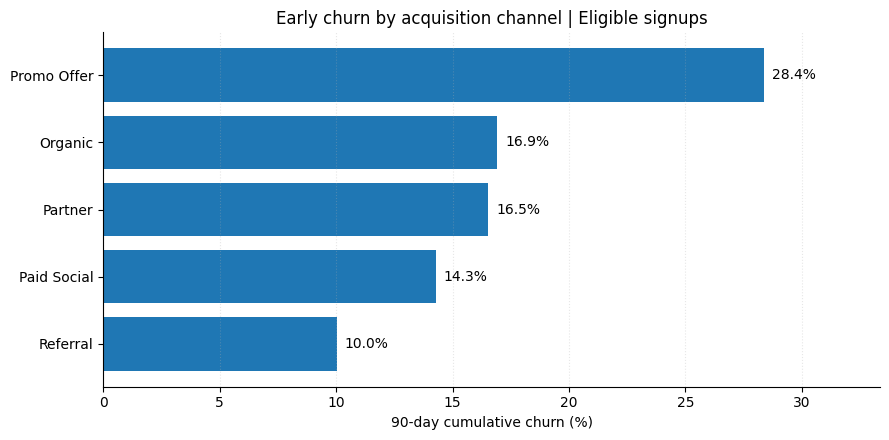

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ordered = channel_rates.sort_values('churn_rate_pct')
ax.barh(ordered.index.str.replace('_', ' ').str.title(), ordered['churn_rate_pct'])
for position, value in enumerate(ordered['churn_rate_pct']):
    ax.text(value + 0.35, position, f'{value:.1f}%', va='center')
ax.set_xlim(0, ordered['churn_rate_pct'].max() + 5)
ax.set_xlabel('90-day cumulative churn (%)')
ax.set_title('Early churn by acquisition channel | Eligible signups')
ax.grid(axis='x', linestyle=':', alpha=0.3)
plt.tight_layout()
plt.show()

**Finding.** Promo Offer has the highest early churn (**28.36%**) and Referral the lowest (**10.02%**). The gap persists among monthly subscribers (**43.90% vs. 15.17%**), suggesting the overall difference is not explained solely by a greater share of monthly subscriptions in promotional acquisition.

### 4.5 Primary device and age group

The device and age comparisons use the same eligible population and 90-day outcome. Device effects are additionally split by plan type.

In [18]:
device_rates = segment_churn(early_eligible, 'primary_device')
device_by_plan = segment_churn(early_eligible, ['primary_device', 'plan_type'])
age_rates = segment_churn(early_eligible, 'age_group')
display(device_rates, device_by_plan, age_rates)

,users,cancellations,churn_rate_pct
primary_device,,,
android,1445,287,19.86
ios,1844,333,18.06
web,626,86,13.74


users  cancellations  churn_rate_pct
primary_device plan_type                                      
android        annual       498             12            2.41
               monthly      947            275           29.04
ios            annual       702             21            2.99
               monthly     1142            312           27.32
web            annual       228              3            1.32
               monthly      398             83           20.85

,users,cancellations,churn_rate_pct
age_group,,,
18-24,666,113,16.97
25-34,1302,239,18.36
35-44,1008,171,16.96
45-54,575,122,21.22
55+,364,61,16.76


**Finding.** Android early churn is **19.86%** versus **13.74%** for Web, while the highest age-group rate is **21.22%** (ages 45–54). These descriptive gaps are smaller or less consistently interpretable than the leading acquisition and engagement patterns. Differences in customer mix remain possible.

## 5. Engagement Analysis

### 5.1 Merge monthly usage with subscriber attributes

The merged table is at the customer-month grain, not the customer grain. We use distinct customers when calculating user-level metrics, and we do not interpret activity observed after cancellation as a predictor.

In [19]:
engdf = usage.merge(subs, on='customer_id', how='left', validate='many_to_one')
assert len(engdf) == len(usage) == 30525
assert engdf['signup_date'].notna().all()
engdf['signup_month'] = engdf['signup_date'].dt.to_period('M')
first_month = engdf.loc[engdf['month'].dt.to_period('M') == engdf['signup_month']].copy()
assert first_month['customer_id'].is_unique
assert first_month['customer_id'].nunique() == 4200
print(f'Merged monthly records: {len(engdf):,}; signup-month customers: {len(first_month):,}')

Merged monthly records: 30,525; signup-month customers: 4,200


### 5.2 Workout engagement during the signup month

Workout activity is aggregated by **calendar month**. A customer who signs up late in the month has less time to work out. The analysis therefore describes signup-month behavior and should not be interpreted as equal exposure across customers.

In [20]:
engagement_bins = [-1, 0, 2, 5, np.inf]
engagement_labels = ['No activity', 'Low', 'Medium', 'High']
first_month['engagement_group'] = pd.cut(
    first_month['workouts_completed'], bins=engagement_bins,
    labels=engagement_labels,
)
print('Signup-month workout distribution:')
display(first_month['workouts_completed'].describe().round(2))
display((first_month['engagement_group'].value_counts(normalize=True).sort_index() * 100).round(2).to_frame('share_pct'))
assert first_month['engagement_group'].notna().all()

Signup-month workout distribution:


count    4200.00
mean        3.98
std         3.57
min         0.00
25%         1.00
50%         3.00
75%         5.00
max        41.00
Name: workouts_completed, dtype: float64

,share_pct
engagement_group,
No activity,9.21
Low,32.81
Medium,33.07
High,24.90


### 5.3 Subsequent 90-day churn after signup month

Separate the **engagement measurement month** from the later outcome window:

1. Exclude customers whose subscription was canceled before the next calendar month.
2. Include only customers with 90 days of potential follow-up after that month.
3. Measure cancellations within `[next_month_start, next_month_start + 90 days)`.

This avoids overlap between measurement and outcome periods, but does not remove all confounding by signup date, plan type, or acquisition channel.

In [21]:
first_month['next_month_start'] = (first_month['signup_month'] + 1).dt.to_timestamp()
engagement_eligible = first_month.loc[
    first_month['churn_date'].isna() |
    (first_month['churn_date'] >= first_month['next_month_start'])
].copy()

followup_cutoff = OBS_END - pd.Timedelta(days=90)
engagement_90 = engagement_eligible.loc[
    engagement_eligible['next_month_start'] <= followup_cutoff
].copy()
engagement_90['followup_end'] = engagement_90['next_month_start'] + pd.Timedelta(days=90)
engagement_90['churn_next_90d'] = (
    (engagement_90['churn_date'] >= engagement_90['next_month_start']) &
    (engagement_90['churn_date'] < engagement_90['followup_end'])
)
assert len(engagement_eligible) == 4049
assert len(engagement_90) == 3754
assert engagement_90['churn_next_90d'].sum() == 661
print(f'Eligible follow-up customers: {len(engagement_90):,}')
print(f'Next-90-day cancellations: {engagement_90.churn_next_90d.sum():,}')
print(f'Subsequent 90-day churn: {engagement_90.churn_next_90d.mean() * 100:.2f}%')

Eligible follow-up customers: 3,754
Next-90-day cancellations: 661
Subsequent 90-day churn: 17.61%


In [22]:
def subsequent_churn(df, columns):
    grouped = df.groupby(columns, observed=True).agg(
        users=('churn_next_90d', 'size'),
        cancellations=('churn_next_90d', 'sum'),
        churn_rate_pct=('churn_next_90d', 'mean'),
    )
    grouped['churn_rate_pct'] = (grouped['churn_rate_pct'] * 100).round(2)
    return grouped

engagement_rates = subsequent_churn(engagement_90, 'engagement_group')
engagement_by_plan = subsequent_churn(engagement_90, ['engagement_group', 'plan_type'])
display(engagement_rates, engagement_by_plan)

,users,cancellations,churn_rate_pct
engagement_group,,,
No activity,317,98,30.91
Low,1223,275,22.49
Medium,1256,203,16.16
High,958,85,8.87


users  cancellations  churn_rate_pct
engagement_group plan_type                                      
No activity      annual       125              7            5.60
                 monthly      192             91           47.40
Low              annual       475             16            3.37
                 monthly      748            259           34.63
Medium           annual       463              7            1.51
                 monthly      793            196           24.72
High             annual       347              2            0.58
                 monthly      611             83           13.58

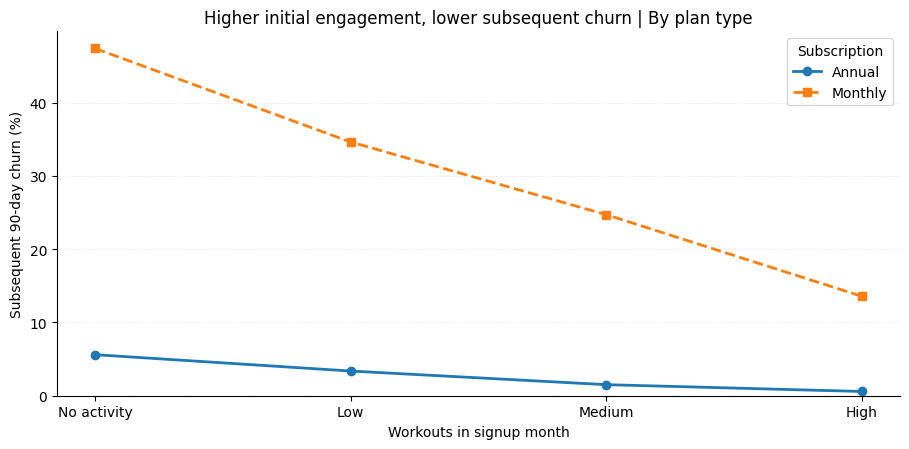

In [23]:
plot_data = engagement_by_plan['churn_rate_pct'].unstack('plan_type')
fig, ax = plt.subplots(figsize=(9.2, 4.6))
x = np.arange(len(plot_data.index))
ax.plot(x, plot_data['annual'], marker='o', linewidth=2, label='Annual')
ax.plot(x, plot_data['monthly'], marker='s', linestyle='--', linewidth=2, label='Monthly')
ax.set_xticks(x)
ax.set_xticklabels(plot_data.index.astype(str))
ax.set_ylim(bottom=0)
ax.set_ylabel('Subsequent 90-day churn (%)')
ax.set_xlabel('Workouts in signup month')
ax.set_title('Higher initial engagement, lower subsequent churn | By plan type')
ax.legend(title='Subscription')
ax.grid(axis='y', linestyle=':', alpha=0.3)
plt.tight_layout()
plt.show()

**Finding.** Churn declines monotonically from **30.91%** with zero workouts to **8.87%** with six or more. The relationship persists for both plan types: **47.40% → 13.58%** across engagement extremes for monthly plans, and **5.60% → 0.58%** for annual plans. The annual high-engagement group has only two observed cancellations; interpret that endpoint cautiously.

### 5.4 Support contact

Support contacts in the signup month are not automatically a signal of failure: an engaged customer might contact support more often. We compare both overall and within plan and workout engagement groups.

In [24]:
engagement_90['had_support_contact'] = engagement_90['support_tickets'] > 0
support_rates = subsequent_churn(engagement_90, 'had_support_contact')
support_by_plan = subsequent_churn(engagement_90, ['had_support_contact', 'plan_type'])
support_by_engagement = subsequent_churn(engagement_90, ['engagement_group', 'had_support_contact'])
display(support_rates, support_by_plan, support_by_engagement)

,users,cancellations,churn_rate_pct
had_support_contact,,,
False,3428,615,17.94
True,326,46,14.11


users  cancellations  churn_rate_pct
had_support_contact plan_type                                      
False               annual      1290             29            2.25
                    monthly     2138            586           27.41
True                annual       120              3            2.50
                    monthly      206             43           20.87

users  cancellations  churn_rate_pct
engagement_group had_support_contact                                      
No activity      False                  294             92           31.29
                 True                    23              6           26.09
Low              False                 1126            257           22.82
                 True                    97             18           18.56
Medium           False                 1135            187           16.48
                 True                   121             16           13.22
High             False                  873             79            9.05
                 True                    85              6            7.06

**Finding.** Subsequent churn is **17.94%** without a support contact versus **14.11%** with one. The direction persists across workout groups, but some support-contact cells are small. This is **not evidence** that support itself prevents cancellations.

### 5.5 Class bookings

The booking association can overlap with general workout participation, so compare booking and no-booking users within the same engagement categories.

In [25]:
engagement_90['had_booking'] = engagement_90['classes_booked'] > 0
booking_rates = subsequent_churn(engagement_90, 'had_booking')
booking_by_engagement = subsequent_churn(engagement_90, ['engagement_group', 'had_booking'])
display(booking_rates, booking_by_engagement)

,users,cancellations,churn_rate_pct
had_booking,,,
False,2580,494,19.15
True,1174,167,14.22


users  cancellations  churn_rate_pct
engagement_group had_booking                                      
No activity      False          317             98           30.91
Low              False          958            219           22.86
                 True           265             56           21.13
Medium           False          783            129           16.48
                 True           473             74           15.64
High             False          522             48            9.20
                 True           436             37            8.49

**Finding.** Booking at least one class is associated with **14.22%** subsequent churn versus **19.15%** for no bookings. Within Low, Medium, and High workout groups, differences narrow to approximately **0.7–1.7 percentage points**, suggesting booking is largely a companion measure of engagement rather than a clearly independent driver.

## 6. Cancellation Reasons

### 6.1 What customers report

Reasons are collected only from canceled subscriptions. Percentages here are **shares of canceled customers**, not churn rates. Keep missing responses in the denominator; they account for a substantial share.

In [26]:
churned_users = subs.loc[subs['churned'] == 'yes'].copy()
reason_counts = churned_users['cancel_reason'].fillna('Not specified').value_counts()
reason_table = pd.DataFrame({
    'cancellations': reason_counts,
    'share_pct': (reason_counts / len(churned_users) * 100).round(2),
})
assert reason_table['cancellations'].sum() == 1768
display(reason_table)

,cancellations,share_pct
cancel_reason,,
not_using_enough,570,32.24
Not specified,382,21.61
too_expensive,322,18.21
found_alternative,175,9.90
other,162,9.16
technical_issues,157,8.88


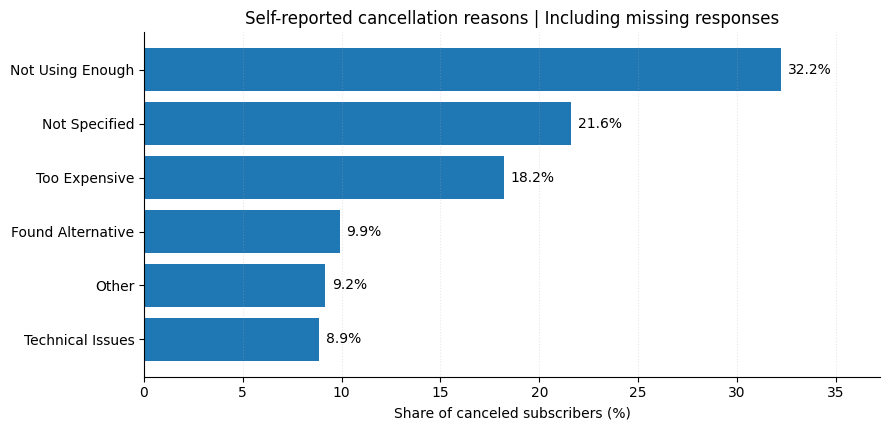

In [27]:
fig, ax = plt.subplots(figsize=(9, 4.4))
reason_plot = reason_table.sort_values('share_pct')
ax.barh(reason_plot.index.str.replace('_', ' ').str.title(), reason_plot['share_pct'])
for i, value in enumerate(reason_plot['share_pct']):
    ax.text(value + 0.35, i, f'{value:.1f}%', va='center')
ax.set_xlim(0, reason_plot['share_pct'].max() + 5)
ax.set_xlabel('Share of canceled subscribers (%)')
ax.set_title('Self-reported cancellation reasons | Including missing responses')
ax.grid(axis='x', linestyle=':', alpha=0.3)
plt.tight_layout()
plt.show()

**Finding.** **Not using enough** is the most common recorded reason (**570 users, 32.24% of all cancellations**). **382 users (21.61%)** did not specify a reason. Among respondents only, insufficient usage accounts for **41.13%**.

### 6.2 Compare reported reasons with actual signup-month workouts

This comparison uses activity in the *first calendar month*, not workouts immediately before the cancellation, which may occur much later.

In [28]:
reason_activity = (
    first_month.loc[first_month['churned'] == 'yes']
    .groupby('cancel_reason', dropna=False)['workouts_completed']
    .agg(users='count', avg_workouts='mean', median_workouts='median')
)
reason_activity['avg_workouts'] = reason_activity['avg_workouts'].round(2)
display(reason_activity)

,users,avg_workouts,median_workouts
cancel_reason,,,
found_alternative,175,3.44,3.0
not_using_enough,570,2.39,2.0
other,162,3.51,3.0
technical_issues,157,3.31,3.0
too_expensive,322,3.74,3.0
NaN,382,2.90,2.0


**Finding.** Subscribers reporting `not_using_enough` averaged **2.39** signup-month workouts (median **2**), compared with **3.74** (median **3**) among those citing `too_expensive`. This is consistent with, but does not prove, the importance of engagement for retention.

### 6.3 Reasons by subscription plan and acquisition channel

Compare distributions **within** plan/channel among canceled subscriptions. These percentages must not be interpreted as unconditional cancellation probabilities.

In [29]:
reasons_by_plan_count = (
    churned_users.groupby(['cancel_reason', 'plan_type'], dropna=False)
        .size().unstack('plan_type', fill_value=0)
)
reasons_by_plan_pct = (
    reasons_by_plan_count.div(reasons_by_plan_count.sum(axis=0), axis=1) * 100
).round(2)

reasons_by_channel_count = (
    churned_users.groupby(['acquisition_channel', 'cancel_reason'], dropna=False)
        .size().unstack('cancel_reason', fill_value=0)
)
reasons_by_channel_pct = (
    reasons_by_channel_count.div(reasons_by_channel_count.sum(axis=1), axis=0) * 100
).round(2)
display(reasons_by_plan_pct, reasons_by_channel_pct)

plan_type,annual,monthly
cancel_reason,,
found_alternative,7.39,10.65
not_using_enough,31.53,32.45
other,7.39,9.69
technical_issues,13.30,7.56
too_expensive,16.75,18.65
NaN,23.65,21.00


cancel_reason,found_alternative,not_using_enough,other,technical_issues,too_expensive,NaN
acquisition_channel,,,,,,
organic,10.71,35.53,11.65,9.40,12.22,20.49
paid_social,13.51,31.69,9.35,8.57,15.84,21.04
partner,11.27,29.90,10.29,8.82,16.18,23.53
promo_offer,5.39,29.88,4.56,9.13,28.42,22.61
referral,10.30,32.73,12.73,7.27,15.76,21.21


**Finding.** Price is cited by **28.42%** of Promo Offer cancellations versus **12.22%** of Organic cancellations, consistent with possible price sensitivity among promotion-acquired customers. Annual cancellations do **not** report high price more often than monthly cancellations overall (**16.75% vs. 18.65%**).

### 6.4 Annual-plan cancellations near first anniversary

Compare reasons among annual-plan cancellations at days 300–359 versus all other observed tenure stages.

In [30]:
annual_churned = churned_users.loc[churned_users['plan_type'] == 'annual'].copy()
annual_churned['period_group'] = np.where(
    annual_churned['tenure_days'].between(300, 359),
    'Days 300–359', 'Other periods'
)
reasons_annual_count = (
    annual_churned.groupby(['period_group', 'cancel_reason'], dropna=False)
        .size().unstack('cancel_reason', fill_value=0)
)
reasons_annual_pct = (
    reasons_annual_count.div(reasons_annual_count.sum(axis=1), axis=0) * 100
).round(2)
assert reasons_annual_count.loc['Days 300–359'].sum() == 306
display(reasons_annual_pct)

cancel_reason,found_alternative,not_using_enough,other,technical_issues,too_expensive,NaN
period_group,,,,,,
Days 300–359,7.84,29.08,5.56,15.36,16.34,25.82
Other periods,6.00,39.00,13.00,7.00,18.00,17.00


**Finding.** Price is **not** cited more often near the first anniversary (**16.34%** vs. **18.00%** in other periods). Technical issues are reported more often (**15.36%** vs. **7.00%**), but the data do not identify renewal problems. Missing reasons are also more frequent near this period (**25.82%** vs. **17.00%**). The spike's mechanism remains unresolved.

## 7. Three Main Churn Factors

The factors below are prioritized by **size and consistency of association**, actionability, and supporting cancellation reasons. These findings span different observation windows and **should not be ranked by raw percentages across incompatible denominators**.

| Factor | Evidence | Consistency check | Qualification |
|---|---|---|---|
| **Low signup-month workout engagement** | Subsequent 90-day churn **30.91% vs. 8.87%** (zero vs. 6+ workouts) | Declining churn across workout groups **within annual and monthly plans**; `not_using_enough` is the most reported reason | Signup month has unequal time available; association does not prove causality |
| **Promo Offer acquisition** | Initial 90-day churn **28.36% vs. 10.02%** (Promo vs. Referral) | Within monthly plans **43.90% vs. 15.17%**; price complaints disproportionately common among canceled Promo users | Channel groups may differ in motivation, offer conditions, and other characteristics |
| **Annual-plan lifecycle near first anniversary** | At days 330–359, preliminary interval cancellation proportion **42.54%** for annual vs. **4.31%** for monthly | Same tenure interval is compared for both plan types; concentration also visible at days 300–329 | Within-interval censoring, no renewal-event data, and no established cause |

**Why not the other candidates?** Plan-tier differences were small; the booking association largely weakened after grouping by workout engagement; support contact and device showed descriptive differences but less robust or less actionable evidence.

**Interpretation guardrail:** The three items above are *churn-associated factors* and target segments for testing, not definitive causal drivers. No machine-learning model or causal experiment was required for this assignment.

## 8. Business Recommendations | One-page Leadership Brief

**Decision:** Prioritize two near-term retention experiments and one targeted investigation of annual-plan cancellations. The analysis covers **4,200** subscribers observed through **December 31, 2025**.

**Priority 1 — Improve onboarding for low-engagement subscribers.** Customers with **zero signup-month workouts** had **30.91%** churn over the following 90 days versus **8.87%** for those with **6+ workouts**. Test personalized first-week workout plans, a simple first-class prompt, and reminders for users completing fewer than three workouts. **Primary KPI:** subsequent 90-day churn, measured on comparable eligible cohorts. **Leading KPI:** share completing at least three workouts during onboarding. **Guardrail:** notification opt-outs and complaints.

**Priority 2 — Retain monthly Promo Offer customers.** Their initial 90-day churn was **43.90%** versus **15.17%** for Referral monthly customers. Among canceled Promo customers, **28.42%** cited price. Test clearer post-promotion pricing communication and an onboarding experience tailored to promotion-acquired members. **Primary KPI:** first-90-day churn for new monthly Promo subscribers. **Business guardrails:** revenue per acquired subscriber and conversion to paid plans.

**Priority 3 — Investigate annual cancellations before the first anniversary.** In the **330–359-day** tenure interval, the preliminary cancellation proportion for annual plans was **42.54%**, compared with **4.31%** for monthly plans. Review renewal journeys and collect structured cancellation feedback, then test value summaries and timely renewal communications. **Primary KPI:** cancellations around the first anniversary among age-matched annual cohorts. **Supporting KPI:** annual renewal rate once actual renewal records are available.

**Measurement plan.** Randomize eligible members into treatment and control groups for retention changes whenever feasible. Use the same time horizons, plan-type strata, and pre-specified success/guardrail measures; assess retention *and* revenue rather than optimizing activity alone. The observed associations are **not causal evidence**. Study limitations include incomplete signup-month exposure, approximate tenure interval estimates, absent renewal-event data, and **21.61%** missing cancellation reasons.